In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

In [2]:
# 1.Load Titanic Dataset

df = sns.load_dataset('titanic')

print("FIRST FIVE RECORDS")
print(df.head())

print("\nDATASET INFORMATION")
print(df.info())

FIRST FIVE RECORDS
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   

In [3]:
# 2. Data Cleaning
df.drop_duplicates(inplace=True)

print("\nDUPLICATE VALUES REMOVED")
print("Dataset Shape:", df.shape)


DUPLICATE VALUES REMOVED
Dataset Shape: (784, 15)


In [4]:
#Select Required Columns 
df = df[['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']].copy()

In [5]:
# 3. Missing Value Handling
print("\nMISSING VALUES BEFORE HANDLING")
print(df.isnull().sum())


MISSING VALUES BEFORE HANDLING
survived      0
pclass        0
sex           0
age         106
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64


In [6]:
# Fill numerical missing values with median
num_cols = ['age', 'fare', 'sibsp', 'parch']

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values with mode
cat_cols = ['sex', 'embarked']

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMISSING VALUES AFTER HANDLING")
print(df.isnull().sum())


MISSING VALUES AFTER HANDLING
survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64


In [7]:
# 4. Feature Scaling
scaler = StandardScaler()

df[num_cols] = scaler.fit_transform(df[num_cols])

print("\nDATA AFTER FEATURE SCALING")
print(df.head())


DATA AFTER FEATURE SCALING
   survived  pclass     sex       age     sibsp     parch      fare embarked
0         0       3    male -0.557360  0.484009 -0.497157 -0.526825        S
1         1       1  female  0.608298  0.484009 -0.497157  0.701587        C
2         1       3  female -0.265945 -0.530599 -0.497157 -0.513876        S
3         1       1  female  0.389737  0.484009 -0.497157  0.352760        S
4         0       3    male  0.389737 -0.530599 -0.497157 -0.511478        S


In [8]:
# 5. Encoding Techniques

# Label Encoding
df['sex'] = df['sex'].map({
    'male': 0,
    'female': 1
})

# One-Hot Encoding
df = pd.get_dummies(
    df,
    columns=['embarked'],
    dtype=int
)

print("\nDATA AFTER ENCODING")
print(df.head())


DATA AFTER ENCODING
   survived  pclass  sex       age     sibsp     parch      fare  embarked_C  \
0         0       3    0 -0.557360  0.484009 -0.497157 -0.526825           0   
1         1       1    1  0.608298  0.484009 -0.497157  0.701587           1   
2         1       3    1 -0.265945 -0.530599 -0.497157 -0.513876           0   
3         1       1    1  0.389737  0.484009 -0.497157  0.352760           0   
4         0       3    0  0.389737 -0.530599 -0.497157 -0.511478           0   

   embarked_Q  embarked_S  
0           0           1  
1           0           0  
2           0           1  
3           0           1  
4           0           1  


In [9]:
# 6. Statistical Analysis
print("\nSTATISTICAL ANALYSIS")
print(df.describe())

print("\nMEAN")
print(df.mean())

print("\nMEDIAN")
print(df.median())


STATISTICAL ANALYSIS
         survived      pclass         sex           age         sibsp  \
count  784.000000  784.000000  784.000000  7.840000e+02  7.840000e+02   
mean     0.411990    2.243622    0.373724  1.540718e-16 -4.984675e-17   
std      0.492507    0.855056    0.484101  1.000638e+00  1.000638e+00   
min      0.000000    1.000000    0.000000 -2.129540e+00 -5.305986e-01   
25%      0.000000    1.000000    0.000000 -5.573596e-01 -5.305986e-01   
50%      0.000000    3.000000    0.000000 -1.020247e-01 -5.305986e-01   
75%      1.000000    3.000000    1.000000  4.625904e-01  4.840095e-01   
max      1.000000    3.000000    1.000000  3.668148e+00  7.586267e+00   

              parch          fare  embarked_C  embarked_Q  embarked_S  
count  7.840000e+02  7.840000e+02  784.000000  784.000000  784.000000  
mean   2.039185e-17 -6.910572e-17    0.197704    0.075255    0.727041  
std    1.000638e+00  1.000638e+00    0.398522    0.263971    0.445764  
min   -4.971569e-01 -6.659087e-0

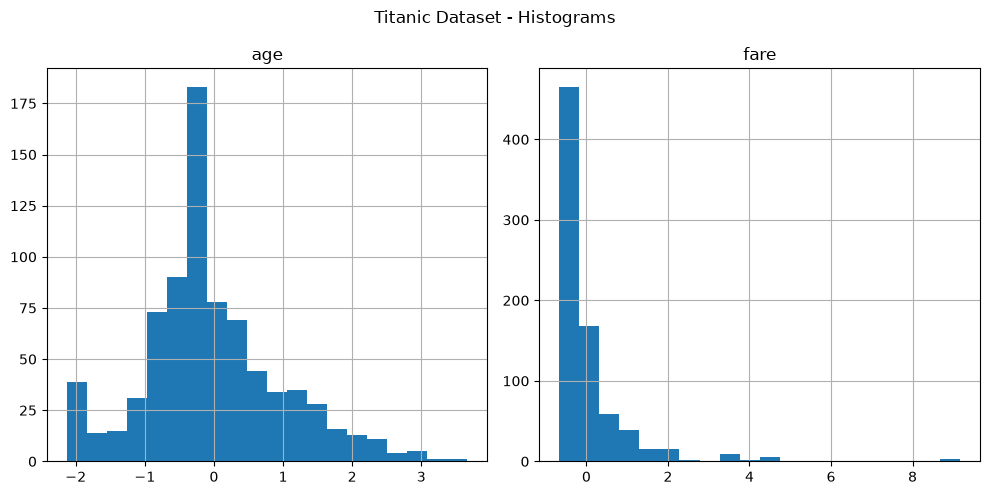

In [10]:
# 7. Data Visualization - Histograms
df[['age', 'fare']].hist(figsize=(10, 5), bins=20)

plt.suptitle("Titanic Dataset - Histograms")
plt.tight_layout()
plt.show()


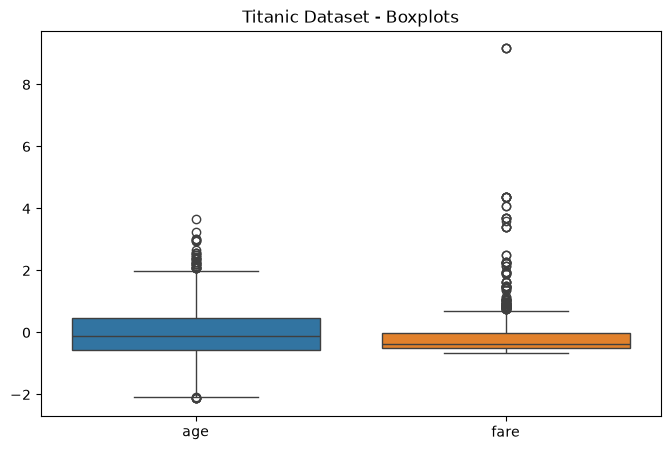


DATA PREPROCESSING AND EDA COMPLETED


In [11]:
# 8. Data Visualization - Boxplots
plt.figure(figsize=(8, 5))

sns.boxplot(data=df[['age', 'fare']])

plt.title("Titanic Dataset - Boxplots")
plt.show()

print("\nDATA PREPROCESSING AND EDA COMPLETED")
